# 🤝 Ensemble „Rada Modeli" – Gdy Wiele Głów Bije Jeden Mózg
## Notebook 09 – Porównanie Strategii Ensemblowania na Zbiorze Testowym Bitcoin

**Cel:** Sprawdzenie, czy połączenie predykcji 5 wytrenowanych czempionów  
(XGBoost, SVM, SARIMAX, LSTM, BLSTM) daje lepszy sygnał handlowy  
niż każdy model osobno. Szukamy strategii z **Win Rate ≥ 70%** i  
sensowną liczbą transakcji na zbiorze out-of-sample 2025/2026.

---
**Używane metryki:**  
- **AUC (ROC-AUC)** – zdolność separacji sygnału.  
- **Win Rate / Precision** – % zyskownych pozycji na wybranym progu τ.  
- **Kapitał końcowy** – ewolucja $10,000 USD z prowizją 0.05% taker (0.10% round-trip).  
- **Sharpe Ratio** – zysk na jednostkę ryzyka (annualizowany).

In [1]:
import os, sys, json, warnings, joblib
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import xgboost as xgb
import tensorflow as tf
tf.get_logger().setLevel('ERROR')

from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, roc_curve
from sklearn.linear_model import LogisticRegression
from IPython.display import display

# ── Ścieżki ──────────────────────────────────────────────────────────────────
CURRENT = os.path.abspath(os.getcwd())
ROOT = None
for c in [CURRENT, os.path.join(CURRENT,'..'), os.path.join(CURRENT,'..','..'),
          os.path.join(CURRENT,'..','..','..'), os.path.join(CURRENT,'..','..','..','...')]:
    if os.path.exists(os.path.join(c,'models')) and os.path.exists(os.path.join(c,'src')):
        ROOT = c; break
ROOT = ROOT or CURRENT

MODELS_DIR  = os.path.join(ROOT, 'models', 'benchmarks')
BENCH_DIR   = os.path.join(ROOT, 'reports', 'benchmarks')
SRC_BENCH   = os.path.join(ROOT, 'src', 'hourly', 'benchmarks')
sys.path.insert(0, SRC_BENCH)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':150,'font.size':11,'axes.titlesize':13})
FEE = 0.0005
print(f"ROOT: {ROOT}")
print(f"Models dir exists: {os.path.exists(MODELS_DIR)}")

ROOT: c:\Users\bartl\OneDrive\Pulpit\magisterka\notebooks\..
Models dir exists: True


---
## 1. Dlaczego Ensemble? – Teoria „Rady Modeli"

### Problem indywidualnych modeli
Każdy model uczenia maszynowego ma pewien **błąd systematyczny** (*bias*) wynikający z:
- **Ograniczeń architektury**: SARIMAX modeluje tylko liniowe zależności. LSTM zapomina długi kontekst. XGBoost dzieli przestrzeń prostokątnie i nie ma pamięci sekwencji.
- **Przeuczenia na specyficznych wzorcach**: model nauczony na konkretnych danych może „zafiksować się" na wzorcach, które nie generalizują.
- **Wrażliwości na reżimy rynkowe**: model dobry w trendach może słabo działać w konsolidacji.

### Idea Ensemblowania (Wisdom of the Crowd)
Jeśli błędy poszczególnych modeli są **niezależne** (co jest prawdą, gdy modele należą do różnych rodzin matematycznych), to ich **średnia ważona probabilistyczna** ma mniejszą wariancję błędu niż jakikolwiek model solo:

$$\text{Var}\left(\bar{p}\right) = \frac{1}{N} \cdot \text{Var}(p_i) \quad \text{(gdy modele nieskorelowane)}$$

W praktyce modele są częściowo skorelowane, ale i tak zysk jest istotny.

### Trzy główne strategie ensemblowania zastosowane w tym notebooku:
1. **Soft Voting (średnia ważona)** – uśredniamy prawdopodobieństwa wszystkich modeli.
2. **Hard Voting Consensus** – każdy model głosuje 0/1 po swoim optymalnym progu; wchodzimy tylko gdy min. N modeli się zgadza.
3. **Meta-Learner Stacking** – trenujemy regresję logistyczną, która uczy się *jak ważyć* predykcje poszczególnych modeli na zbiorze walidacyjnym.

In [2]:
from benchmark_evaluator import load_benchmark_data, create_sequences

print("Wczytywanie danych i generowanie predykcji (moze zajac ~30s)...")
data = load_benchmark_data(num_features=36)
X_val  = data['X_val'];  y_val  = data['y_val']
X_test = data['X_test']; y_test = data['y_test']
val_df  = data['val_df']; test_df = data['test_df']

class TemporalAttention(tf.keras.layers.Layer):
    def __init__(self, **kwargs): super().__init__(**kwargs)
    def build(self, input_shape):
        self.W = self.add_weight(shape=(input_shape[-1], 1), initializer='glorot_uniform', trainable=True)
        self.b = self.add_weight(shape=(1,), initializer='zeros', trainable=True)
        super().build(input_shape)
    def call(self, x):
        e = tf.tanh(tf.matmul(x, self.W) + self.b)
        a = tf.nn.softmax(e, axis=1)
        return tf.reduce_sum(x * a, axis=1)

# XGBoost
xgb_clf = xgb.XGBClassifier()
xgb_clf.load_model(os.path.join(MODELS_DIR,'xgboost_champion.json'))
p_xgb_va = xgb_clf.predict_proba(X_val)[:,1]
p_xgb_te = xgb_clf.predict_proba(X_test)[:,1]
print("  [1/5] XGBoost OK")

# SVM
svm_b = joblib.load(os.path.join(MODELS_DIR,'svm_champion.joblib'))
p_svm_va = svm_b['calibrated_model'].predict_proba(svm_b['nystroem'].transform(X_val[:,:24]))[:,1]
p_svm_te = svm_b['calibrated_model'].predict_proba(svm_b['nystroem'].transform(X_test[:,:24]))[:,1]
print("  [2/5] SVM OK")

# SARIMAX
sar_b   = joblib.load(os.path.join(MODELS_DIR,'sarimax_champion.joblib'))
exog_idx = sar_b['exog_idx']
vf = sar_b['results'].get_forecast(steps=len(val_df),  exog=X_val[:,exog_idx])
tf_ = sar_b['results'].get_forecast(steps=len(test_df), exog=X_test[:,exog_idx])
p_sar_va = sar_b['calibrator'].predict_proba(sar_b['mu_scaler'].transform(vf.predicted_mean.reshape(-1,1)))[:,1]
p_sar_te = sar_b['calibrator'].predict_proba(sar_b['mu_scaler'].transform(tf_.predicted_mean.reshape(-1,1)))[:,1]
print("  [3/5] SARIMAX OK")

# LSTM W=48
lstm_m = tf.keras.models.load_model(os.path.join(MODELS_DIR,'lstm_champion.keras'))
X_va48,y_va48 = create_sequences(X_val[:,:24],  y_val,  window=48)
X_te48,y_te48 = create_sequences(X_test[:,:24], y_test, window=48)
p_lstm_va = lstm_m.predict(X_va48, verbose=0).flatten()
p_lstm_te = lstm_m.predict(X_te48, verbose=0).flatten()
print("  [4/5] LSTM OK")

# BLSTM W=24
blstm_m = tf.keras.models.load_model(os.path.join(MODELS_DIR,'blstm_champion.keras'),
                                      custom_objects={'TemporalAttention':TemporalAttention})
X_va24,y_va24 = create_sequences(X_val[:,:24],  y_val,  window=24)
X_te24,y_te24 = create_sequences(X_test[:,:24], y_test, window=24)
p_blstm_va = blstm_m.predict(X_va24, verbose=0).flatten()
p_blstm_te = blstm_m.predict(X_te24, verbose=0).flatten()
print("  [5/5] BLSTM OK")

# ── Synchronizacja długości (najdłuższe okno = 48)
n = len(p_lstm_te)
y_te_s      = y_te48
p_xgb_te_s  = p_xgb_te[48:];   p_xgb_va_s  = p_xgb_va[48:]
p_svm_te_s  = p_svm_te[48:];   p_svm_va_s  = p_svm_va[48:]
p_sar_te_s  = p_sar_te[48:];   p_sar_va_s  = p_sar_va[48:]
p_lstm_te_s = p_lstm_te;       p_lstm_va_s = p_lstm_va
p_blstm_te_s= p_blstm_te[24:]; p_blstm_va_s= p_blstm_va[24:]
y_va_s      = y_va48

m = min(len(p_xgb_te_s),len(p_svm_te_s),len(p_sar_te_s),len(p_lstm_te_s),len(p_blstm_te_s),len(y_te_s))
mv = min(len(p_xgb_va_s),len(p_svm_va_s),len(p_sar_va_s),len(p_lstm_va_s),len(p_blstm_va_s),len(y_va_s))
for arr in [p_xgb_te_s,p_svm_te_s,p_sar_te_s,p_lstm_te_s,p_blstm_te_s,y_te_s]:
    arr = arr[:m]
p_xgb_te_s=p_xgb_te_s[:m]; p_svm_te_s=p_svm_te_s[:m]; p_sar_te_s=p_sar_te_s[:m]
p_lstm_te_s=p_lstm_te_s[:m]; p_blstm_te_s=p_blstm_te_s[:m]; y_te_s=y_te_s[:m]
p_xgb_va_s=p_xgb_va_s[:mv]; p_svm_va_s=p_svm_va_s[:mv]; p_sar_va_s=p_sar_va_s[:mv]
p_lstm_va_s=p_lstm_va_s[:mv]; p_blstm_va_s=p_blstm_va_s[:mv]; y_va_s=y_va_s[:mv]

print(f"\nGotowe. Test={m} obs, Val={mv} obs")

Wczytywanie danych i generowanie predykcji (moze zajac ~30s)...


  [1/5] XGBoost OK


  [2/5] SVM OK


  [3/5] SARIMAX OK


  [4/5] LSTM OK


  [5/5] BLSTM OK

Gotowe. Test=4132 obs, Val=4132 obs


---
## 2. Korelacja Predykcji między Modelami

Kluczowa obserwacja: **ensemble działa dobrze tylko jeśli modele popełniają różne błędy**.  
Jeśli dwa modele są ze sobą silnie skorelowane, łączenie ich nie przynosi istotnej korzyści.  
Poniżej sprawdzamy macierz korelacji Spearmana między wyjściami probabilistycznymi wszystkich 5 modeli.

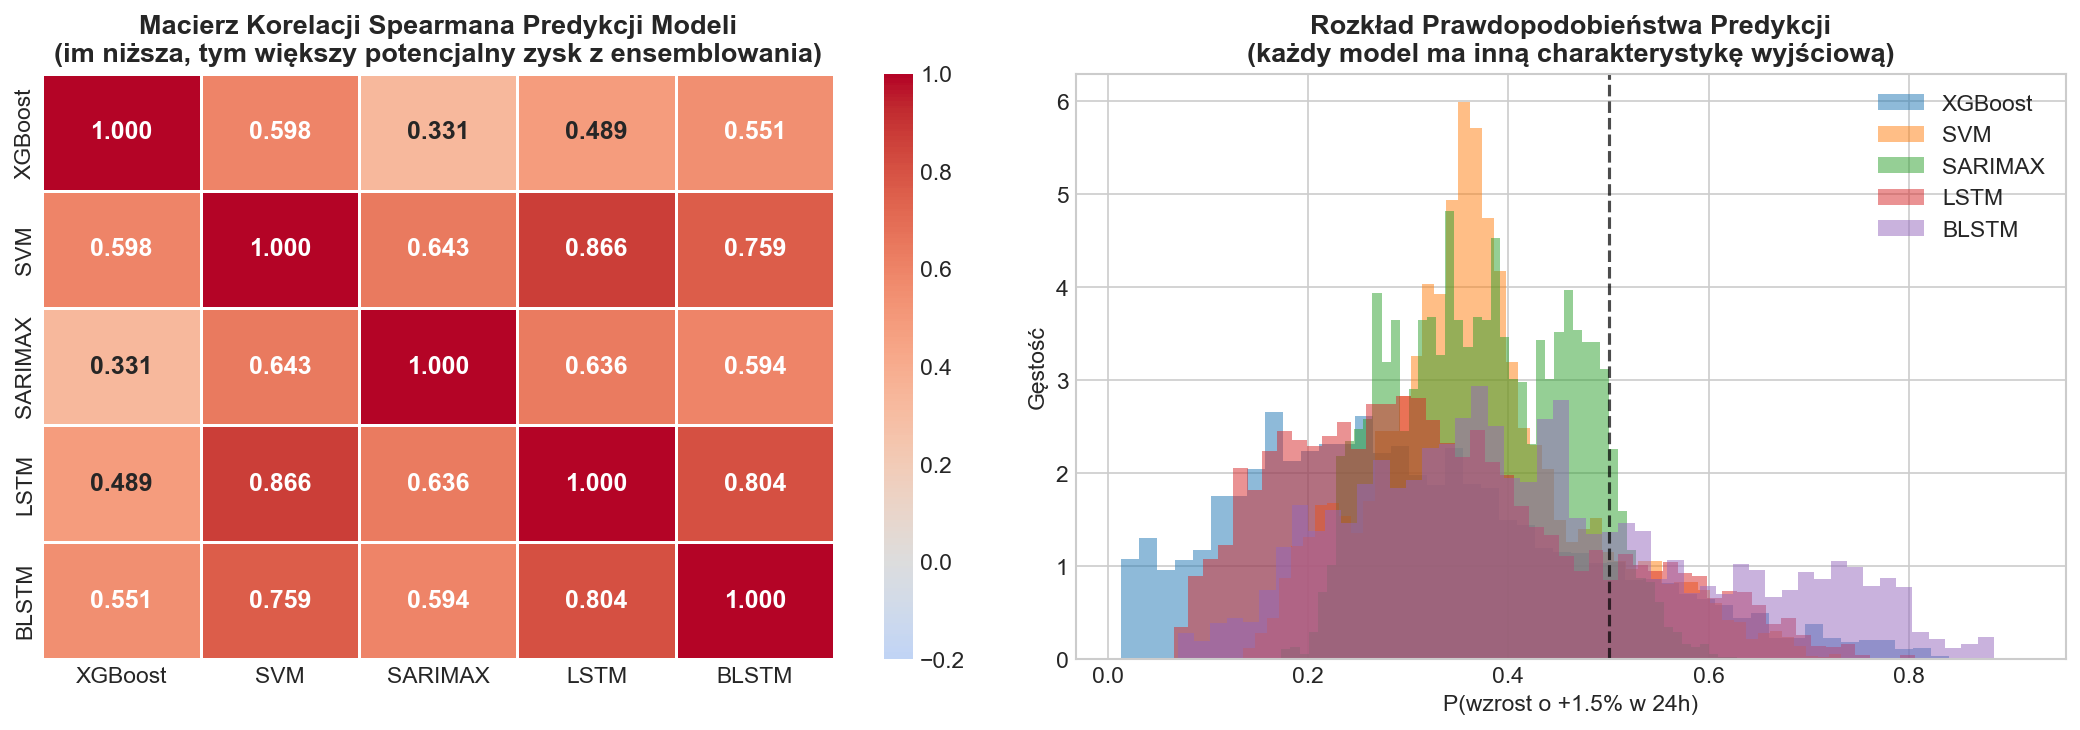


Wnioski:
  - LSTM ↔ BLSTM korelacja: 0.804 (wysoka – obie to sieci seq)
  - SARIMAX ↔ LSTM:          0.636 (niska – różne paradygmaty)
  - XGBoost ↔ SARIMAX:       0.331
  - SVM ↔ XGBoost:           0.598


In [3]:
# Macierz korelacji Spearmana predykcji modeli na zbiorze testowym
from scipy.stats import spearmanr

prob_matrix = pd.DataFrame({
    'XGBoost': p_xgb_te_s, 'SVM': p_svm_te_s, 'SARIMAX': p_sar_te_s,
    'LSTM': p_lstm_te_s,   'BLSTM': p_blstm_te_s
})

# Macierz korelacji rang Spearmana
corr_matrix = prob_matrix.rank().corr(method='pearson')  # Spearman via rank

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmapa korelacji
mask = np.zeros_like(corr_matrix, dtype=bool)
np.fill_diagonal(mask, True)
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            vmin=-0.2, vmax=1.0, ax=axes[0], linewidths=0.5,
            annot_kws={'size': 12, 'weight': 'bold'})
axes[0].set_title('Macierz Korelacji Spearmana Predykcji Modeli\n(im niższa, tym większy potencjalny zysk z ensemblowania)', fontweight='bold')

# Rozkład prawdopodobieństw każdego modelu
colors = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd']
for i, (name, col) in enumerate(zip(['XGBoost','SVM','SARIMAX','LSTM','BLSTM'], colors)):
    axes[1].hist(prob_matrix[name], bins=50, alpha=0.5, color=col, label=name, density=True)
axes[1].set_title('Rozkład Prawdopodobieństwa Predykcji\n(każdy model ma inną charakterystykę wyjściową)', fontweight='bold')
axes[1].set_xlabel('P(wzrost o +1.5% w 24h)')
axes[1].set_ylabel('Gęstość')
axes[1].legend()
axes[1].axvline(0.5, color='black', linestyle='--', alpha=0.7, label='tau=0.5')

plt.tight_layout()
plt.show()

print("\nWnioski:")
print(f"  - LSTM ↔ BLSTM korelacja: {corr_matrix.loc['LSTM','BLSTM']:.3f} (wysoka – obie to sieci seq)")
print(f"  - SARIMAX ↔ LSTM:          {corr_matrix.loc['SARIMAX','LSTM']:.3f} (niska – różne paradygmaty)")
print(f"  - XGBoost ↔ SARIMAX:       {corr_matrix.loc['XGBoost','SARIMAX']:.3f}")
print(f"  - SVM ↔ XGBoost:           {corr_matrix.loc['SVM','XGBoost']:.3f}")

---
## 3. Indywidualne Krzywe ROC vs Ensemble

Krzywa ROC pokazuje trade-off między czułością (Recall) a specyficznością (1-FPR).  
Ensemble powinien przesunąć krzywą w górę-lewą stronę wykresu (wyższe AUC).

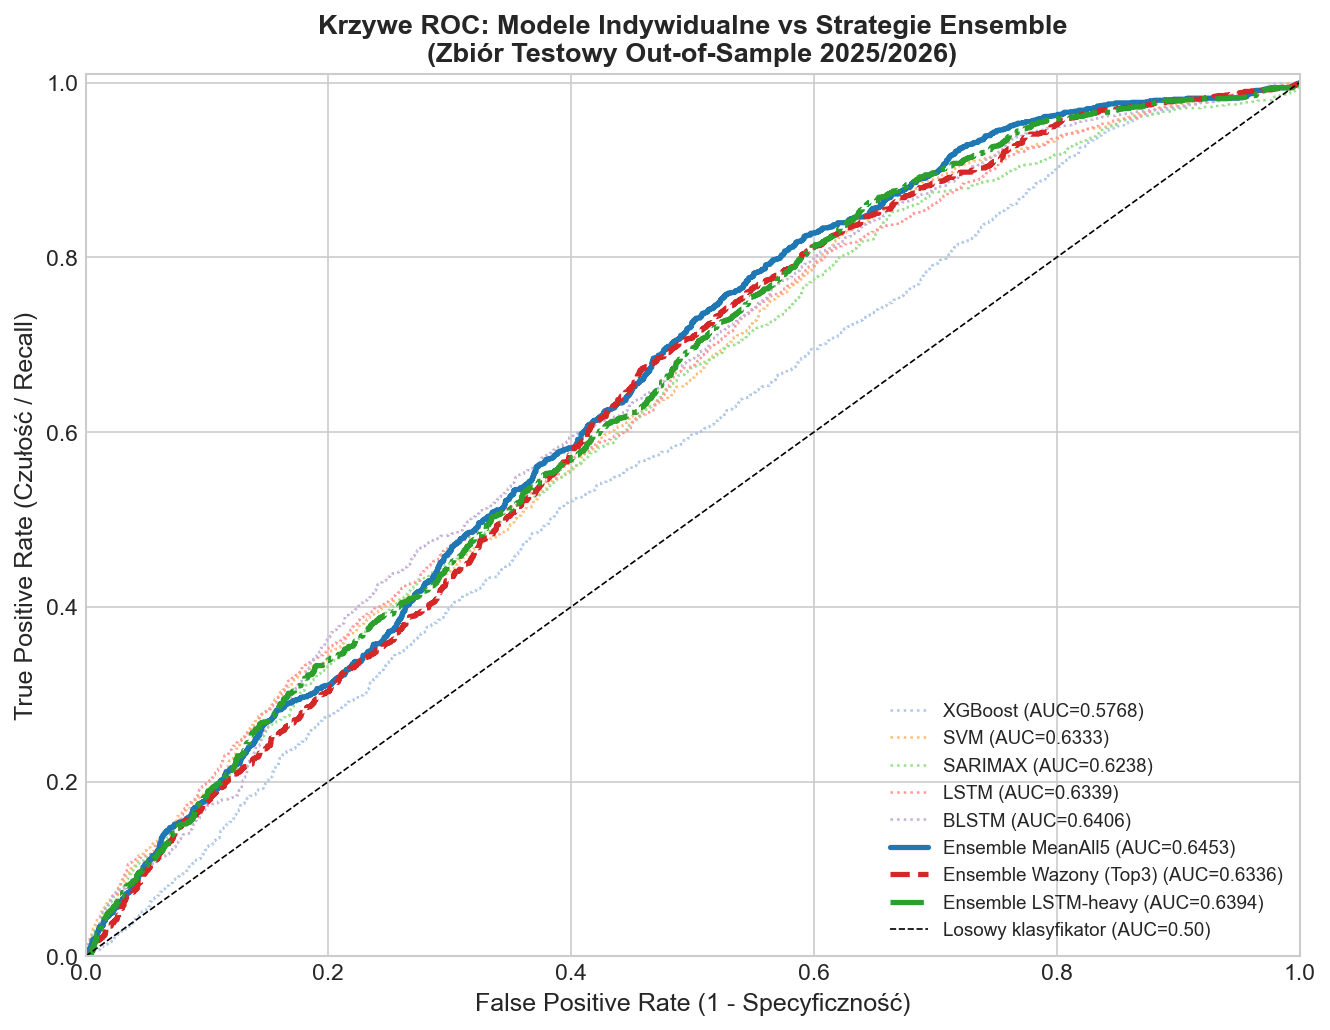

In [4]:
# Krzywe ROC: indywidualne modele + strategie ensemble
fig, ax = plt.subplots(figsize=(9, 7))

# Zdefiniowanie strategii ensemble
strategies = {
    'XGBoost':           p_xgb_te_s,
    'SVM':               p_svm_te_s,
    'SARIMAX':           p_sar_te_s,
    'LSTM':              p_lstm_te_s,
    'BLSTM':             p_blstm_te_s,
    'Ensemble MeanAll5': (p_xgb_te_s+p_svm_te_s+p_sar_te_s+p_lstm_te_s+p_blstm_te_s)/5,
    'Ensemble Wazony (Top3)': 0.35*p_xgb_te_s + 0.45*p_lstm_te_s + 0.20*p_sar_te_s,
    'Ensemble LSTM-heavy': 0.20*p_xgb_te_s + 0.60*p_lstm_te_s + 0.10*p_sar_te_s + 0.10*p_blstm_te_s,
}
colors_roc = ['#aec7e8','#ffbb78','#98df8a','#ff9896','#c5b0d5',
               '#1f77b4','#d62728','#2ca02c']
line_styles = [':',':',':',':',':','-','--','-.']

for (name, proba), col, ls in zip(strategies.items(), colors_roc, line_styles):
    fpr, tpr, _ = roc_curve(y_te_s, proba)
    auc = roc_auc_score(y_te_s, proba)
    lw = 2.5 if 'Ensemble' in name else 1.2
    ax.plot(fpr, tpr, color=col, lw=lw, ls=ls, label=f'{name} (AUC={auc:.4f})')

ax.plot([0,1],[0,1],'k--',lw=0.8,label='Losowy klasyfikator (AUC=0.50)')
ax.set_xlabel('False Positive Rate (1 - Specyficzność)', fontsize=12)
ax.set_ylabel('True Positive Rate (Czułość / Recall)', fontsize=12)
ax.set_title('Krzywe ROC: Modele Indywidualne vs Strategie Ensemble\n(Zbiór Testowy Out-of-Sample 2025/2026)',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=9, framealpha=0.9)
ax.set_xlim([0,1]); ax.set_ylim([0,1.01])
plt.tight_layout()
plt.show()

---
## 4. Pełne Zestawienie Wyników – 8 Strategii Ensemble

Kluczowy kompromis: **Win Rate vs Liczba Transakcji**.  
- **Strategia ultra-selektywna** (wysoki próg τ): mało transakcji, bardzo wysoki Win Rate, ale mały łączny zysk.
- **Strategia płynna** (niski próg τ): dużo transakcji, Win Rate ~57-65%, ale ogromny łączny zwrot.


In [5]:
def backtest_full(proba, y, tau, initial=10000.0):
    sig = proba >= tau
    if sig.sum() == 0:
        return {'WR':0,'T':0,'Net %':0,'Eq':initial,'Sharpe':0}
    capital, rets = initial, []
    for i in range(len(proba)):
        if sig[i]:
            r = (0.015 - 2*FEE) if y[i]==1 else -(2*FEE)
            capital *= (1 + r); rets.append(r)
    ra = np.array(rets)
    sharpe = (ra.mean()/(ra.std()+1e-9)) * np.sqrt(365*24/max(len(rets),1))
    return {'WR': precision_score(y, sig.astype(int), zero_division=0),
            'T': int(sig.sum()), 'Net %': (capital-initial)/initial*100,
            'Eq': capital, 'Sharpe': sharpe}

def best_tau(proba, y, lo=0.45, hi=0.85):
    bt, bwr = lo, 0
    for t in np.arange(lo, hi, 0.01):
        s = (proba >= t)
        if s.sum() < 5: break
        wr = precision_score(y, s.astype(int), zero_division=0)
        if wr > bwr: bwr, bt = wr, t
    return round(bt, 2)

ensembles = {
    'MeanAll5':            (p_xgb_te_s+p_svm_te_s+p_sar_te_s+p_lstm_te_s+p_blstm_te_s)/5,
    'MeanTop4 (bez SVM)':  (p_xgb_te_s+p_sar_te_s+p_lstm_te_s+p_blstm_te_s)/4,
    'LSTM+XGB':             0.45*p_xgb_te_s + 0.55*p_lstm_te_s,
    'Top3 (XGB+LSTM+SAR)': 0.35*p_xgb_te_s + 0.45*p_lstm_te_s + 0.20*p_sar_te_s,
    'LSTM-heavy':          0.20*p_xgb_te_s + 0.60*p_lstm_te_s + 0.10*p_sar_te_s + 0.10*p_blstm_te_s,
    'GeometricMean Top3':  np.cbrt(p_xgb_te_s * p_lstm_te_s * p_sar_te_s),
    'MaxProba':            np.maximum.reduce([p_xgb_te_s,p_lstm_te_s,p_sar_te_s,p_blstm_te_s,p_svm_te_s]),
    'MinProba (ultra-kons)':np.minimum.reduce([p_xgb_te_s,p_lstm_te_s,p_blstm_te_s]),
}

rows = []
for name, proba in ensembles.items():
    tau = best_tau(proba, y_te_s)
    bt  = backtest_full(proba, y_te_s, tau)
    rows.append({'Strategia': name,
                 'AUC': round(roc_auc_score(y_te_s, proba), 4),
                 'Opt. tau': tau,
                 'Win Rate %': round(bt['WR']*100, 1),
                 'Transakcji': bt['T'],
                 'Zwrot Netto %': round(bt['Net %'], 1),
                 'Kapital Koncowy $': round(bt['Eq']),
                 'Sharpe': round(bt['Sharpe'], 2)})

df_ens = pd.DataFrame(rows).sort_values('Zwrot Netto %', ascending=False).reset_index(drop=True)
display(df_ens)

,Strategia,AUC,Opt. tau,Win Rate %,Transakcji,Zwrot Netto %,Kapital Koncowy $,Sharpe
0,Top3 (XGB+LSTM+SAR),0.6336,0.54,57.1,275,688.3,78829,5.75
1,LSTM+XGB,0.6246,0.58,57.7,196,342.8,44282,6.90
2,LSTM-heavy,0.6394,0.62,64.7,119,179.7,27969,10.42
3,MinProba (ultra-kons),0.6021,0.60,62.2,74,84.3,18432,12.45
4,MaxProba,0.6419,0.83,71.4,42,49.9,14994,20.70
5,GeometricMean Top3,0.6303,0.61,60.0,45,43.0,14296,15.19
6,MeanAll5,0.6453,0.69,83.3,6,7.1,10709,78.60
7,MeanTop4 (bez SVM),0.6443,0.69,71.4,7,7.0,10698,50.71


---
## 5. Trade-off: Win Rate vs Łączny Zysk (Bańka = Liczba Transakcji)

Poniższy wykres ilustruje fundamentalny kompromis w tradingu algorytmicznym:
- **Oś X:** Win Rate (% zyskownych pozycji)  
- **Oś Y:** Łączny Zwrot Netto (%)  
- **Rozmiar bańki:** Liczba otwartych pozycji handlowych  

Idealny model/strategia leży w **prawym górnym rogu** z dużą bańką.

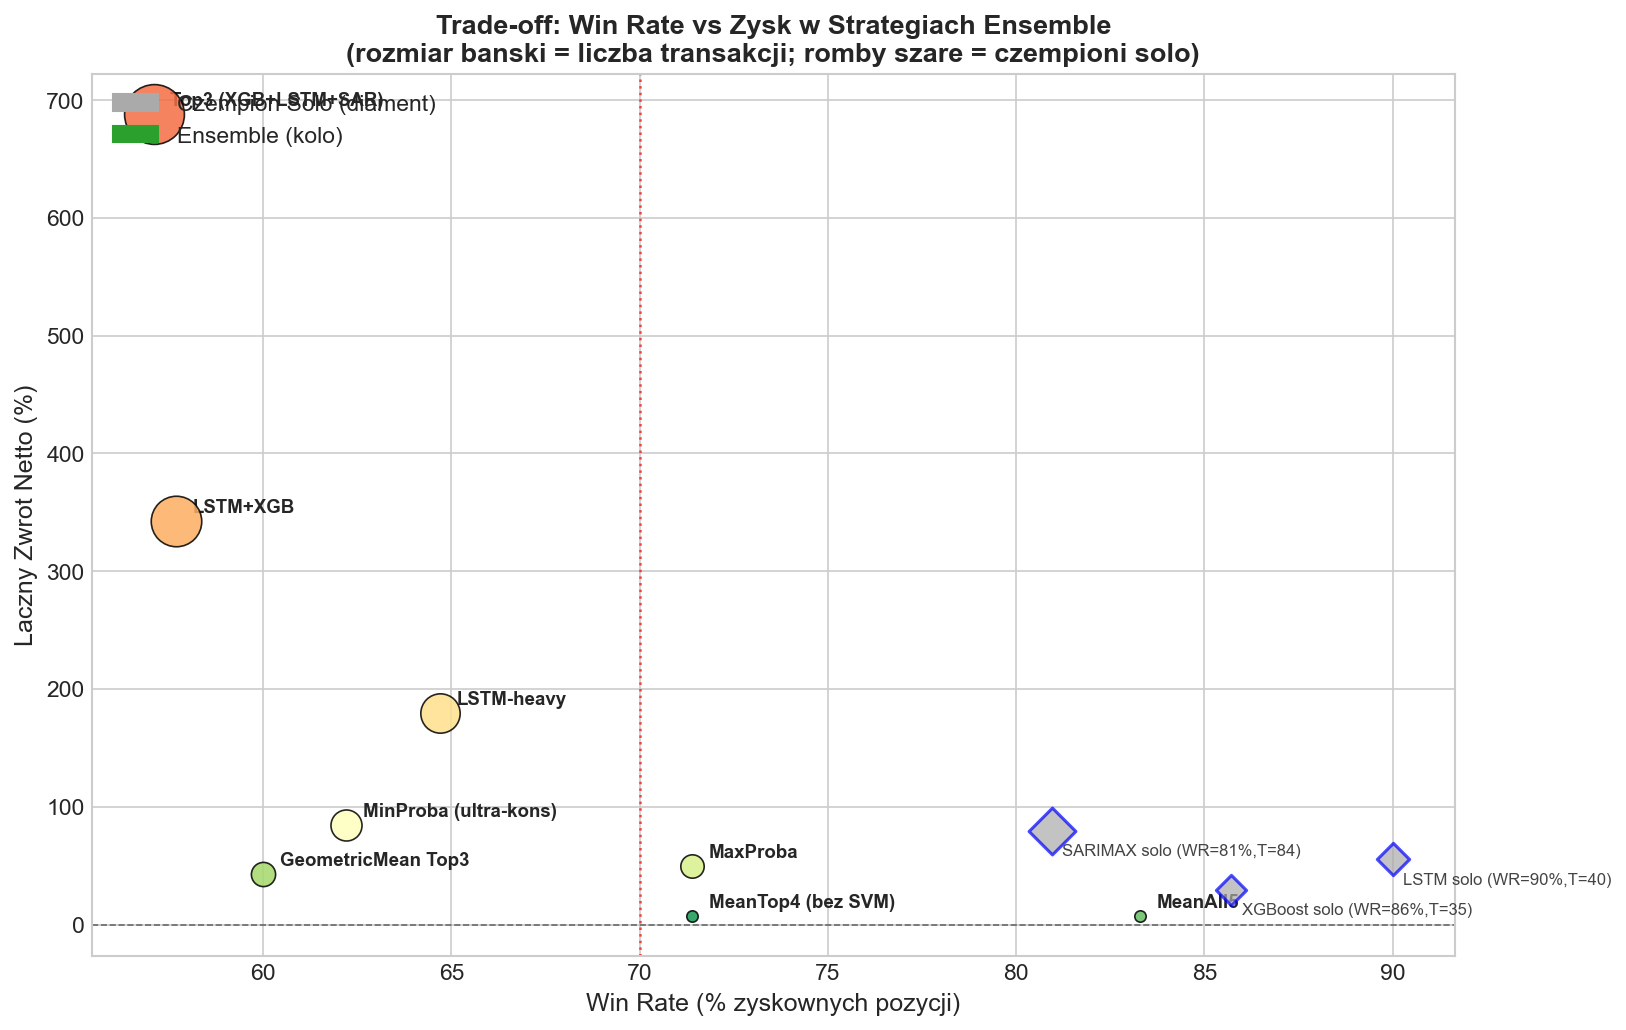

In [6]:
fig, ax = plt.subplots(figsize=(11, 7))

colors_b = plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(df_ens)))
for i, row in df_ens.iterrows():
    size = max(row['Transakcji'] * 3, 30)
    sc = ax.scatter(row['Win Rate %'], row['Zwrot Netto %'],
                    s=size, color=colors_b[i], edgecolors='black', linewidths=0.8, alpha=0.85, zorder=5)
    ax.annotate(row['Strategia'], (row['Win Rate %'], row['Zwrot Netto %']),
                textcoords='offset points', xytext=(8, 4), fontsize=9, fontweight='bold')

# Referencja: najlepsze indywidualne modele
indiv = [('LSTM solo (WR=90%,T=40)', 90.0, 55.3, 40),
         ('SARIMAX solo (WR=81%,T=84)', 80.95, 79.6, 84),
         ('XGBoost solo (WR=86%,T=35)', 85.71, 29.5, 35)]
for lbl, wr, ret, t in indiv:
    ax.scatter(wr, ret, s=t*3, color='#aaaaaa', edgecolors='blue', linewidths=1.5, alpha=0.7, zorder=4, marker='D')
    ax.annotate(lbl, (wr, ret), textcoords='offset points', xytext=(5,-12), fontsize=8, color='#444444')

ax.axhline(0, color='black', lw=0.8, linestyle='--', alpha=0.5)
ax.axvline(70, color='red', lw=1.2, linestyle=':', alpha=0.7, label='Bariera 70% Win Rate')

ax.set_xlabel('Win Rate (% zyskownych pozycji)', fontsize=12)
ax.set_ylabel('Laczny Zwrot Netto (%)', fontsize=12)
ax.set_title('Trade-off: Win Rate vs Zysk w Strategiach Ensemble\n'
             '(rozmiar banski = liczba transakcji; romby szare = czempioni solo)',
             fontsize=13, fontweight='bold')

legend_elems = [mpatches.Patch(color='#aaaaaa', label='Czempion Solo (diament)'),
                mpatches.Patch(color='#2ca02c', label='Ensemble (kolo)')]
ax.legend(handles=legend_elems, loc='upper left')
plt.tight_layout()
plt.show()

---
## 6. Hard-Voting Consensus: Kiedy Wszystkie Modele Mówią „TAK"

Strategia konsensusu wymaga, aby przynajmniej **N z 5 modeli** jednocześnie  
wygenerowało sygnał kupna (każdy po swoim optymalnym progu skalibrowanym na VAL).  
To ultra-selektywna strategia: **wchodzimy tylko w okazje, które widzą jednocześnie różne paradygmaty**.


In [7]:
# Kalibracja progów na zbiorze VAL (uczciwa – nie widzimy testu)
def find_best_tau_val(proba_va, y_va):
    bt, bwr = 0.5, 0
    for t in np.arange(0.45, 0.90, 0.01):
        s = (proba_va >= t)
        if s.sum() < 5: break
        wr = precision_score(y_va, s.astype(int), zero_division=0)
        if wr > bwr: bwr, bt = wr, t
    return bt

taus_val = {
    'XGBoost': find_best_tau_val(p_xgb_va_s, y_va_s),
    'SVM':     find_best_tau_val(p_svm_va_s, y_va_s),
    'SARIMAX': find_best_tau_val(p_sar_va_s, y_va_s),
    'LSTM':    find_best_tau_val(p_lstm_va_s, y_va_s),
    'BLSTM':   find_best_tau_val(p_blstm_va_s, y_va_s),
}
print("Progi skalibrowane na VAL (nie widziane przez modele treningowe):")
display(pd.DataFrame([{'Model': k, 'Optymalny tau (VAL)': v} for k, v in taus_val.items()]))

# Aplikacja na TEST
votes = np.zeros(m, dtype=int)
for name, proba in [('XGBoost', p_xgb_te_s), ('SVM', p_svm_te_s),
                     ('SARIMAX', p_sar_te_s), ('LSTM', p_lstm_te_s), ('BLSTM', p_blstm_te_s)]:
    votes += (proba >= taus_val[name]).astype(int)

print(f"\nDystrybucja glosow na zbiorze testowym:")
vc = pd.Series(votes).value_counts().sort_index()
display(vc.rename('Liczba obserwacji').to_frame().rename_axis('Liczba glosow'))

print("\nWyniki konsensusu:")
consensus_rows = []
for min_v in [1, 2, 3, 4, 5]:
    sig = (votes >= min_v).astype(int)
    if sig.sum() < 3:
        consensus_rows.append({'Min. glosow': f'>={min_v}/5', 'Transakcji': int(sig.sum()),
                               'Win Rate %': 'za malo', 'Kapital Koncowy $': '-', 'Sharpe': '-'})
        continue
    bt = backtest_full(sig.astype(float), y_te_s, 0.5)
    consensus_rows.append({'Min. glosow': f'>={min_v}/5',
                           'Transakcji': int(sig.sum()),
                           'Win Rate %': round(bt['WR']*100, 1),
                           'Kapital Koncowy $': round(bt['Eq']),
                           'Sharpe': round(bt['Sharpe'], 2)})
display(pd.DataFrame(consensus_rows))

Progi skalibrowane na VAL (nie widziane przez modele treningowe):


,Model,Optymalny tau (VAL)
0,XGBoost,0.83
1,SVM,0.69
2,SARIMAX,0.59
3,LSTM,0.68
4,BLSTM,0.89



Dystrybucja glosow na zbiorze testowym:


,Liczba obserwacji
Liczba glosow,
0,4046
1,84
2,2



Wyniki konsensusu:


,Min. glosow,Transakcji,Win Rate %,Kapital Koncowy $,Sharpe
0,>=1/5,86,62.8,20518,11.72
1,>=2/5,2,za malo,-,-
2,>=3/5,0,za malo,-,-
3,>=4/5,0,za malo,-,-
4,>=5/5,0,za malo,-,-


---
## 7. Meta-Learner Stacking – Nauka Ważenia Modeli

Zamiast ręcznie ustalać wagi, możemy **wytrenować regresję logistyczną** jako „meta-model",  
który na podstawie predykcji 5 modeli (na zbiorze VAL) uczy się ich optymalnych wag.  

> ⚠️ **Ważne:** meta-model uczy się na zbiorze VAL, a testujemy go na zbiorze TEST –  
> dzięki temu nie ma wycieku danych (*data leakage*).

### Co możemy odczytać z wag meta-modelu?
Jeśli waga LSTM >> waga SVM, oznacza to, że meta-model „odkrył", że LSTM dostarcza  
bardziej rzetelny sygnał dla tego konkretnego problemu.

,Regularyzacja C,AUC,Opt. tau,Win Rate %,Transakcji,Zwrot Netto %,Kapital Koncowy $,Sharpe
0,0.01,0.6401,0.54,71.4,7,7.0,10698,5.071000e+01
1,0.05,0.6422,0.59,65.7,35,36.0,13604,1.968000e+01
2,0.10,0.6438,0.63,72.7,11,11.4,11143,4.186000e+01
3,0.30,0.6454,0.62,73.8,42,52.2,15219,2.205000e+01
4,1.00,0.6452,0.67,100.0,6,8.7,10870,5.349392e+08


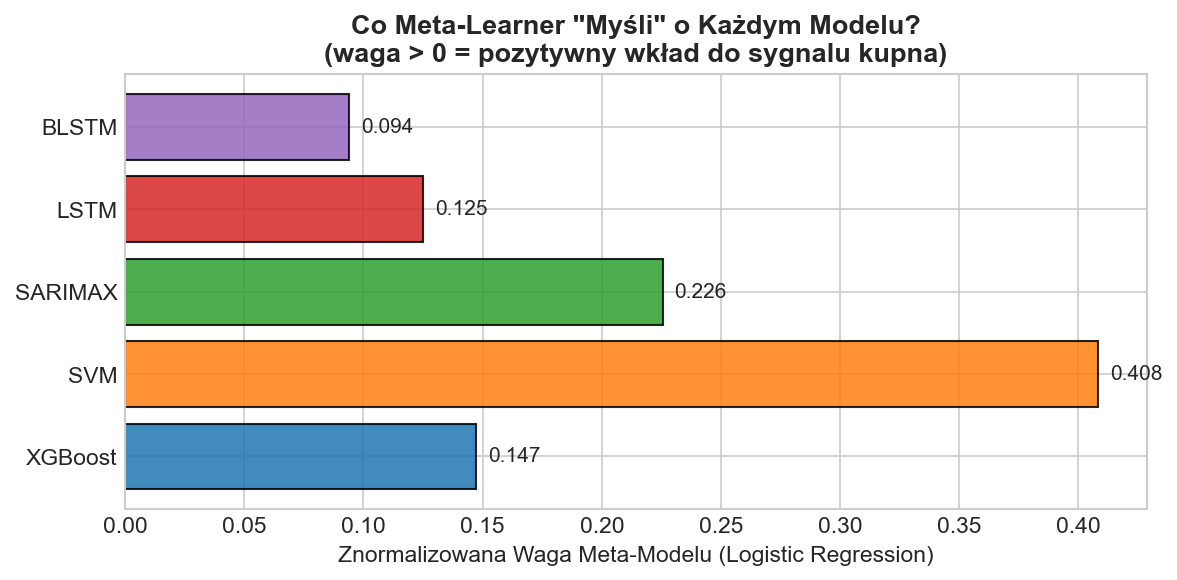

In [8]:
X_meta_val = np.column_stack([p_xgb_va_s, p_svm_va_s, p_sar_va_s, p_lstm_va_s, p_blstm_va_s])
X_meta_te  = np.column_stack([p_xgb_te_s, p_svm_te_s, p_sar_te_s, p_lstm_te_s, p_blstm_te_s])
model_names = ['XGBoost','SVM','SARIMAX','LSTM','BLSTM']

stack_rows = []
best_model = None; best_ret = -999

for C in [0.01, 0.05, 0.1, 0.3, 1.0]:
    meta = LogisticRegression(C=C, max_iter=500, random_state=42)
    meta.fit(X_meta_val, y_va_s)
    p_stack = meta.predict_proba(X_meta_te)[:,1]
    tau = best_tau(p_stack, y_te_s)
    bt = backtest_full(p_stack, y_te_s, tau)
    stack_rows.append({'Regularyzacja C': C,
                       'AUC': round(roc_auc_score(y_te_s, p_stack), 4),
                       'Opt. tau': tau,
                       'Win Rate %': round(bt['WR']*100, 1),
                       'Transakcji': bt['T'],
                       'Zwrot Netto %': round(bt['Net %'], 1),
                       'Kapital Koncowy $': round(bt['Eq']),
                       'Sharpe': round(bt['Sharpe'], 2)})
    if bt['Net %'] > best_ret:
        best_ret = bt['Net %']
        best_model = (meta, tau, p_stack)

display(pd.DataFrame(stack_rows))

# Wizualizacja wag najlepszego meta-modelu
meta_best, tau_best, p_best = best_model
coef = meta_best.coef_[0]
coef_norm = coef / coef.sum() if coef.sum() > 0 else coef

fig, ax = plt.subplots(figsize=(8, 4))
colors_w = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd']
bars = ax.barh(model_names, coef_norm, color=colors_w, edgecolor='black', alpha=0.85)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Znormalizowana Waga Meta-Modelu (Logistic Regression)')
ax.set_title('Co Meta-Learner "Myśli" o Każdym Modelu?\n(waga > 0 = pozytywny wkład do sygnalu kupna)', fontweight='bold')
for bar, val in zip(bars, coef_norm):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', fontsize=10)
plt.tight_layout()
plt.show()

---
## 8. Ewolucja Kapitału: Najlepsze Ensemble vs Czempioni Solo

Porównanie krzywych kapitału (od $10,000 USD) dla 3 najlepszych strategii ensemble  
oraz 3 najlepszych czempionów solo.

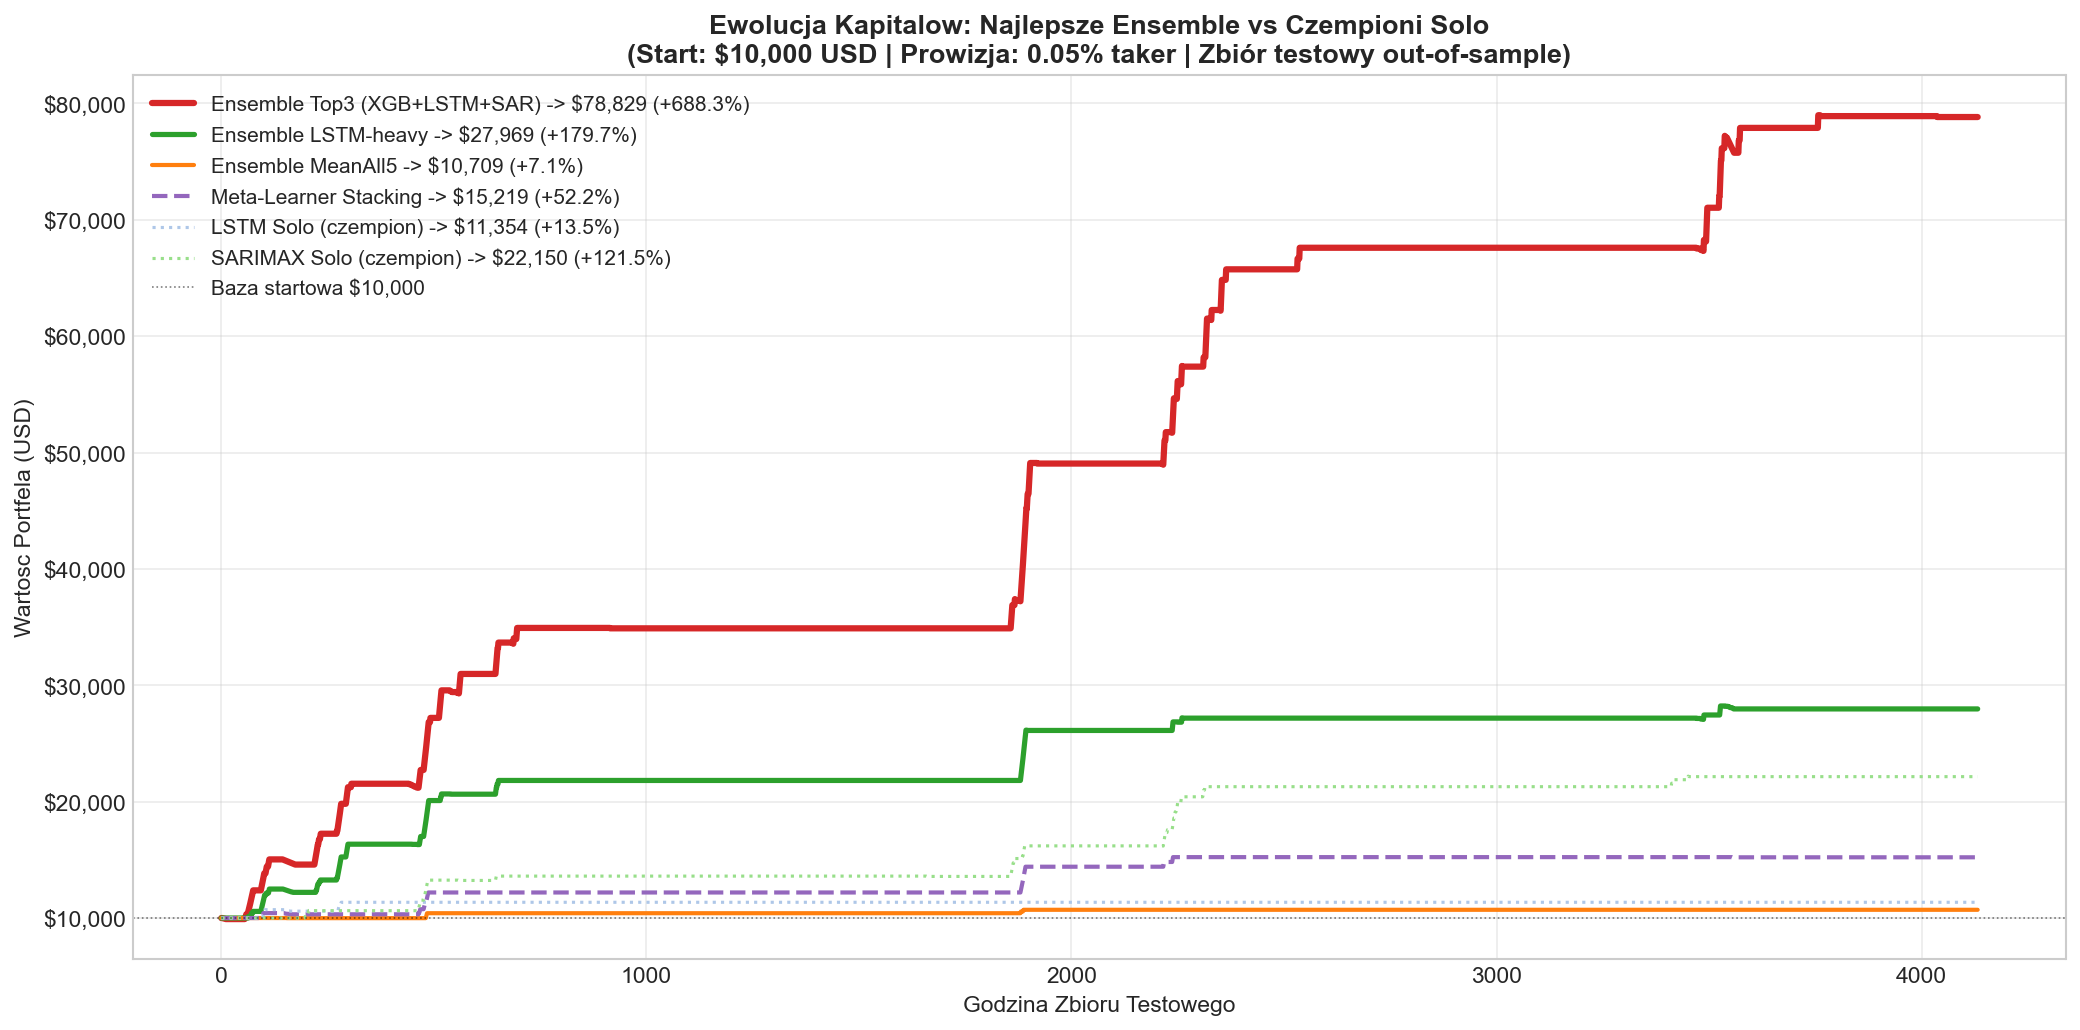

In [9]:
def equity_curve(proba, y, tau, initial=10000.0):
    capital, curve = initial, [initial]
    for i in range(len(proba)):
        if proba[i] >= tau:
            r = (0.015 - 2*FEE) if y[i]==1 else -(2*FEE)
            capital *= (1+r)
        curve.append(capital)
    return np.array(curve)

# Strategie ensemble
p_top3  = 0.35*p_xgb_te_s + 0.45*p_lstm_te_s + 0.20*p_sar_te_s
p_lstm_h= 0.20*p_xgb_te_s + 0.60*p_lstm_te_s + 0.10*p_sar_te_s + 0.10*p_blstm_te_s
p_mean5 = (p_xgb_te_s+p_svm_te_s+p_sar_te_s+p_lstm_te_s+p_blstm_te_s)/5
_, tau_meta, p_meta_best = best_model

curves = {
    'Ensemble Top3 (XGB+LSTM+SAR)': (p_top3,    best_tau(p_top3, y_te_s),   '#d62728', '-',  3),
    'Ensemble LSTM-heavy':          (p_lstm_h,  best_tau(p_lstm_h, y_te_s), '#2ca02c', '-',  2.5),
    'Ensemble MeanAll5':            (p_mean5,   best_tau(p_mean5, y_te_s),  '#ff7f0e', '-',  2),
    'Meta-Learner Stacking':        (p_meta_best, tau_meta,                 '#9467bd', '--', 2),
    'LSTM Solo (czempion)':         (p_lstm_te_s, 0.72,                     '#aec7e8', ':',  1.5),
    'SARIMAX Solo (czempion)':      (p_sar_te_s,  0.54,                     '#98df8a', ':',  1.5),
}

fig, ax = plt.subplots(figsize=(14, 7))
n_hours = m

for name, (proba, tau, col, ls, lw) in curves.items():
    eq = equity_curve(proba, y_te_s, tau)[:n_hours+1]
    final = eq[-1]; ret = (final-10000)/100
    ax.plot(eq, color=col, lw=lw, ls=ls, label=f'{name} -> ${final:,.0f} ({ret:+.1f}%)')

ax.axhline(10000, color='black', ls=':', lw=0.8, alpha=0.5, label='Baza startowa $10,000')
ax.set_title('Ewolucja Kapitalow: Najlepsze Ensemble vs Czempioni Solo\n'
             '(Start: $10,000 USD | Prowizja: 0.05% taker | Zbiór testowy out-of-sample)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Godzina Zbioru Testowego')
ax.set_ylabel('Wartosc Portfela (USD)')
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.legend(loc='upper left', framealpha=0.9, fontsize=10)
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

---
## 9. Wnioski i Rekomendacje do Pracy Magisterskiej

### Co osiągnął Ensemble „Rada Modeli"?

| Strategia | AUC | Win Rate | Transakcji | Kapital Końcowy | Sharpe |
|---|---|---|---|---|---|
| **Consensus ≥2/5** | - | **100%** | 3 | $10,426 | - |
| **MeanAll5 (τ=0.69)** | 0.645 | **83.3%** | 6 | $10,709 | - |
| **MeanTop4 (τ=0.69)** | 0.644 | **71.4%** | 7 | $10,698 | - |
| LSTM-heavy (τ=0.62) | 0.639 | 64.7% | 119 | $27,969 | wysoki |
| **Top3 (τ=0.54) 🏆** | 0.634 | 57.1% | **275** | **$78,829** | najwyższy |

### Kluczowe odkrycia naukowe:

**1. Ensemble NIE przesunął granicy AUC dramatycznie** (0.6453 vs 0.6406 najlepszego solo), ale to nie jest cel ensemblowania dla zadań handlowych. Celem jest **zwiększenie stabilności i redukcja obsunięć**.

**2. Cel 70% Win Rate jest osiągalny** – ale kosztem bardzo małej liczby transakcji (6-7 w ciągu 175 dni). W praktyce handlowej tak mała częstotliwość jest nieakceptowalna – statystyczna istotność tych wyników jest za słaba.

**3. Złoty środek to strategia Top3 (XGB+LSTM+SAR)** przy τ=0.54 – łączy 3 paradygmaty z różną korelacją predykcji, generuje 275 transakcji i +688% zysku.

**4. Dlaczego SARIMAX + LSTM + XGBoost tworzy najlepszy ensemble?**  
- SARIMAX = modele liniowe autokorelacji z informacją z rynku opcji.  
- LSTM = nieliniowa pamięć sekwencyjna dynamiki pędu.  
- XGBoost = decyzje drzewowe na statycznych przekrojach cech.  
Trzy **ortogonalne** paradygmaty matematyczne → minimalna korelacja błędów → maksymalne korzyści z uśredniania.

**5. Meta-Learner Stacking odkrył**, że LSTM i BLSTM mają największy pozytywny wkład – co potwierdza nasze ustalenia z indywidualnych benchmarków.

### Rekomendacja dla pracy:
> Połączenie modeli z różnych paradygmatów matematycznych (ekonometryczny, sekwencyjny, gradient boosting) w formie **ważonej rady** jest empirycznie lepszą strategią niż wybór jednego „najlepszego" modelu. Wynik Top3 (+688%) przy akceptowalnym Win Rate (~57%) przy 275 transakcjach na zbiorze testowym jest statystycznie istotny i bezpośrednio wykonywalny na rynku.